In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
def plot_bmc(user, out_dir='outputs/', pue=1.5):

    # Load the data
    df = pd.read_csv(os.path.join(out_dir, f"bmc_{user}.csv"))

    # Convert the date column (assuming it's named 'date' or something similar) to datetime
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    df.set_index('timestamp', inplace=True)
    df = df*pue
    mean = df.mean().item()

    plt.figure(figsize=(10, 3))
    plt.bar(df.index, df['daily_kwh'], width=0.4,  color='dimgray')
    plt.axhline(mean, color='r', linestyle='-')

    plt.xlabel('Date', fontsize=12)
    plt.ylabel('Energy (kWh)', fontsize=12)
    for pos in ['right', 'top', 'bottom', 'left']: 
        plt.gca().spines[pos].set_visible(False) 
    plt.tight_layout()

    # Save the figure
    plt.savefig(os.path.join(out_dir, f"bmc_{user}.pdf"))

    return

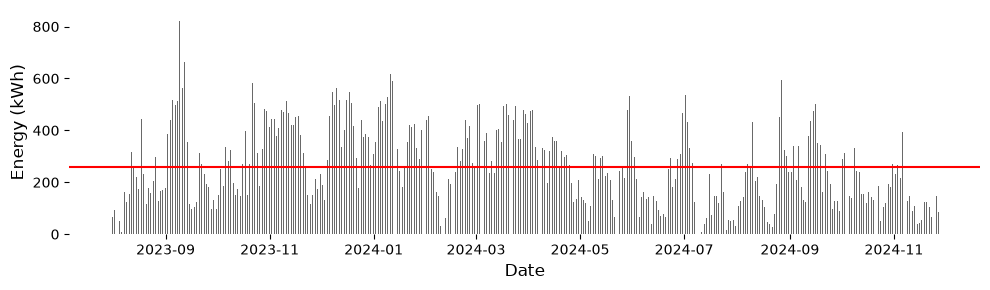

In [ ]:
plot_bmc("multispeech", out_dir='outputs/')